# Marketing Science Empirical Analysis — Step-by-Step Story Progression

Evaluation of `KEV-0.8B`, `KEV-4B`, and `KEV-9B` across the paper's four-step narrative using two universal metrics shared across all benchmarks: **Population Slope MSE ($\beta\text{ MSE}$)** and **Choice-Distribution KL Divergence ($\text{Choice KL}$)**.

### Dataset Roles
- **Training studies**:
  - `Wu 2025` (flight conjoint): either **8 published OLS slopes** (`Row 2`, `Row 4`) or **`18,591` respondent microdata choices** (`Row 2b`, `Row 5`).
  - `Berke` (consumer choice microdata): respondent choices (`Row 3`, `Row 4`, `Row 5`).
- **Validation & checkpoint selection (`best.pt`)**: `Kriner 2026` (flight conjoint, 12 terms).
- **Held-out out-of-domain test sets (`test_best/`)**:
  - `Grummon 2025` (food warning labels, 5 terms).
  - `Kreps 2020` (`Kreps et al. 2020` vaccine conjoint, 11 terms; `1,971` respondents, `9,855` tasks).

### Narrative Roadmap
- **Step 0 — Run & `test_best` Inventory**: Training status (`runs-rorqual/`) and `test_best/` completion.
- **Overview — The Story at a Glance**: Table 0, Figure 0 (in-domain vs. out-of-domain change for every main regime).
- **Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (Untrained vs. `Row 2b`, `Row 3`, `Row 5`)**: Table 1, Figure 1; Choice KL in Table A2.
- **Step 2 — A Published Table Teaches the Study's Slopes (Untrained vs. `Row 2` KL-anchored vs. `Row 2b`)**: Table 2, Figure 2; Choice KL in Table A3.
- **Step 3 — Your Microdata + Another Study's Table (Untrained vs. `Row 3` vs. `Row 4` KL-anchored vs. `Row 5`)**: Table 3, Figure 3; Choice KL in Table A4.
- **Step 4 — What the Errors Look Like (`Kreps 2020` slopes by attribute)**: Figure 4; numbers in Table A5.
- **Ablation — Without the KL Anchor (to be rebuilt)**: `No-KL` runs for `Row 2` and `Row 4`, training trajectories, and the α sweep.

In [125]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cycler import cycler

# Repository academic palette ("nature") & neutral tones (cf. code/analysis/wang2026/wang_mnl.py)
PALETTE_NAME = "lancet"
PALETTES = {
    "nature": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}
NEUTRALS = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}
PAL = PALETTES[PALETTE_NAME]
plt.rcParams["axes.prop_cycle"] = cycler(color=PAL)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
PAPER_DIR = BETA_TRAINING_DIR / "ms_paper_beta_loss"
PAPER_RUNS_ROOT = PAPER_DIR / "runs-rorqual"
LOCAL_PAPER_RUNS_ROOT = PAPER_DIR / "runs"
LEGACY_RUNS_ROOT = BETA_TRAINING_DIR / "runs"
TEST_BEST_SUBDIR = "test_best"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR), str(PAPER_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from beta_ce_population.trainer import load_ce_population_run
from beta_population.trainer import load_population_run
from beta_train import runs as run_store
from beta_train.trainer import load_run
from paper_beta import extract_step0_from_run_dir, load_paper_run

MODEL_SLUGS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_DISPLAY = {
    "kev-0.8b": "KEV-0.8B",
    "kev-4b": "KEV-4B",
    "kev-9b": "KEV-9B",
}
VALIDATORS = ("kriner2026", "grummon2025")

REGIME_LABELS = {
    "row1_base_untrained": "Row 1: Untrained Base",
    "row2_wu_table_anchored": "Row 2: Wu Table (KL = 0.005)",
    "row2_ablation_wu_table_no_kl": "Row 2: Wu Table (No-KL)",
    "row2b_wu_ce_oracle": "Row 2b: Wu Microdata CE (Study Oracle)",
    "row3_berke_ce_only": "Row 3: Berke Microdata CE",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Berke CE + Wu Table (KL = 0.005)",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Berke CE + Wu Table (No-KL)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Full Microdata CE (Full Oracle)",
}
SHORT_COL_LABELS = {
    "row1_base_untrained": "Row 1: Base",
    "row2_ablation_wu_table_no_kl": "Row 2: Wu Table (No-KL)",
    "row2_wu_table_anchored": "Row 2: Wu Table (KL)",
    "row2b_wu_ce_oracle": "Row 2b: Wu CE",
    "row3_berke_ce_only": "Row 3: Berke CE",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Row 4: Hybrid (No-KL)",
    "row4_hybrid_berke_ce_wu_table_anchored": "Row 4: Hybrid (KL)",
    "row5_full_berke_wu_ce_oracle": "Row 5: Full CE",
}
ALL_SLUGS = tuple(REGIME_LABELS.keys())
TRAINED_SLUGS = tuple(k for k in ALL_SLUGS if k != "row1_base_untrained")

DATASET_GROUPS = (
    ("kriner", "Kriner 2026 (Val)"),
    ("grummon", "Grummon 2025 (Test)"),
    ("covid", "Kreps 2020 (Test)"),
)


def load_test_best_entry(run_or_row1_dir: Path, expected_step: int) -> dict | None:
    """Load `test_best/` (`grummon2025` + `covid`) when present and verify checkpoint_step alignment."""
    test_dir = run_or_row1_dir / TEST_BEST_SUBDIR
    test_json = test_dir / "test.json"
    if not test_json.exists():
        return None
    metrics_csv = test_dir / "metrics.csv"
    betas_csv = test_dir / "betas.csv"
    if not metrics_csv.exists() or not betas_csv.exists():
        raise FileNotFoundError(f"Incomplete test_best directory in {test_dir}")

    test_info = json.loads(test_json.read_text(encoding="utf-8"))
    actual_step = int(test_info["checkpoint_step"])
    if actual_step != expected_step:
        raise ValueError(f"Stale test_best in {test_dir}: checkpoint_step={actual_step}, expected {expected_step}")

    metrics_df = pd.read_csv(metrics_csv).set_index("dataset")
    for ds in ("grummon2025", "covid"):
        if ds not in metrics_df.index:
            raise ValueError(f"Dataset {ds!r} missing from {metrics_csv}")

    betas_df = pd.read_csv(betas_csv)
    required_cols = {"validator", "term", "human_pop_beta", "model_pop_beta"}
    if not required_cols.issubset(betas_df.columns):
        raise ValueError(f"Missing columns in {betas_csv}: expected {required_cols}, got {set(betas_df.columns)}")

    return {
        "metrics_df": metrics_df,
        "covid_betas": betas_df[betas_df["validator"] == "covid"].set_index("term"),
        "grummon_betas": betas_df[betas_df["validator"] == "grummon2025"].set_index("term"),
    }


print(f"PAPER_RUNS_ROOT : {PAPER_RUNS_ROOT}")


PAPER_RUNS_ROOT : /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual


---
## Step 0 — Run & `test_best` Completion Inventory

Operational status matrix across `KEV-0.8B`, `KEV-4B`, and `KEV-9B` (omitted from the paper's main tables).


In [126]:
def collect_model_regimes(
    model_slug: str,
) -> tuple[pd.DataFrame, dict[str, pd.DataFrame]]:
    model_dir = PAPER_RUNS_ROOT / model_slug
    existing_dirs = [model_dir / s for s in TRAINED_SLUGS if (model_dir / s / "run.json").exists()]
    if len(existing_dirs) == 0:
        raise FileNotFoundError(f"No canonical regime runs found in {model_dir}")

    step0 = extract_step0_from_run_dir(existing_dirs[0], VALIDATORS)
    covid_betas_by_slug: dict[str, pd.DataFrame] = {}

    row1_tb = load_test_best_entry(model_dir / "row1_base_untrained", expected_step=0)
    if row1_tb is not None:
        g0_tb = float(row1_tb["metrics_df"].loc["grummon2025", "beta_mse"])
        g0_val = step0["metrics"]["grummon2025/beta_mse"]
        if abs(g0_tb - g0_val) > 2e-4:
            raise ValueError(f"{model_slug} Row 1 Grummon mismatch: val={g0_val:.6f} vs test_best={g0_tb:.6f}")
        row1_grummon_mse = g0_tb
        row1_grummon_kl = float(row1_tb["metrics_df"].loc["grummon2025", "kl_loss"])
        row1_covid_mse = float(row1_tb["metrics_df"].loc["covid", "beta_mse"])
        row1_covid_kl = float(row1_tb["metrics_df"].loc["covid", "kl_loss"])
        covid_betas_by_slug["row1_base_untrained"] = row1_tb["covid_betas"]
        row1_progress = "step 0 [test_best ✓]"
    else:
        row1_grummon_mse = step0["metrics"]["grummon2025/beta_mse"]
        row1_grummon_kl = step0["metrics"]["grummon2025/kl_loss"]
        row1_covid_mse = np.nan
        row1_covid_kl = np.nan
        row1_progress = "step 0 [test_best pending]"

    rows = [
        {
            "slug": "row1_base_untrained",
            "regime": REGIME_LABELS["row1_base_untrained"],
            "progress": row1_progress,
            "kriner_mse": step0["metrics"]["kriner2026/beta_mse"],
            "kriner_kl": step0["metrics"]["kriner2026/kl_loss"],
            "grummon_mse": row1_grummon_mse,
            "grummon_kl": row1_grummon_kl,
            "covid_mse": row1_covid_mse,
            "covid_kl": row1_covid_kl,
        }
    ]

    for slug in TRAINED_SLUGS:
        run_dir = model_dir / slug
        if not (run_dir / "run.json").exists():
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": "—",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                }
            )
            continue

        run_info = run_store.read_run_json(run_dir)
        raw_status = run_info["status"]
        result = load_paper_run(run_dir)
        steps_done = len(result.step_df)
        best_step = int(result.best["step"])

        if steps_done == 0:
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": f"{raw_status} (0 steps)",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                }
            )
            continue

        k_metrics, _ = result.best_validation["kriner2026"]
        tb_entry = load_test_best_entry(run_dir, expected_step=best_step)
        if tb_entry is not None:
            g_mse = float(tb_entry["metrics_df"].loc["grummon2025", "beta_mse"])
            g_kl = float(tb_entry["metrics_df"].loc["grummon2025", "kl_loss"])
            if "grummon2025" in result.best_validation:
                g_val = float(result.best_validation["grummon2025"][0]["beta_mse"])
                if abs(g_mse - g_val) > 2e-4:
                    raise ValueError(f"{model_slug}/{slug} Grummon mismatch: val={g_val:.6f} vs test_best={g_mse:.6f}")
            c_mse = float(tb_entry["metrics_df"].loc["covid", "beta_mse"])
            c_kl = float(tb_entry["metrics_df"].loc["covid", "kl_loss"])
            covid_betas_by_slug[slug] = tb_entry["covid_betas"]
            tb_tag = "[test_best ✓]"
        else:
            c_mse = np.nan
            c_kl = np.nan
            tb_tag = "[test_best pending]"
            if "grummon2025" in result.best_validation:
                g_mse = float(result.best_validation["grummon2025"][0]["beta_mse"])
                g_kl = float(result.best_validation["grummon2025"][0]["kl_loss"])
            else:
                g_valid = result.val_history_df["grummon2025/beta_mse"].dropna()
                g_step = int(g_valid.index[np.abs(g_valid.index.to_numpy() - best_step).argmin()])
                g_mse = float(g_valid.loc[g_step])
                g_kl = float(result.val_history_df.loc[g_step, "grummon2025/kl_loss"])

        rows.append(
            {
                "slug": slug,
                "regime": REGIME_LABELS[slug],
                "progress": f"{raw_status} (@{best_step}/{steps_done}) {tb_tag}",
                "kriner_mse": float(k_metrics["beta_mse"]),
                "kriner_kl": float(k_metrics["kl_loss"]),
                "grummon_mse": g_mse,
                "grummon_kl": g_kl,
                "covid_mse": c_mse,
                "covid_kl": c_kl,
            }
        )

    return pd.DataFrame(rows).set_index("slug"), covid_betas_by_slug


regimes_by_model: dict[str, pd.DataFrame] = {}
covid_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
for model_slug in MODEL_SLUGS:
    regimes_by_model[model_slug], covid_betas_by_model[model_slug] = collect_model_regimes(model_slug)

status_grid = pd.DataFrame(
    {MODEL_DISPLAY[m]: regimes_by_model[m].loc[list(ALL_SLUGS), "progress"].values for m in MODEL_SLUGS},
    index=[REGIME_LABELS[s] for s in ALL_SLUGS],
)
status_grid.index.name = "Regime"
display(status_grid)


,KEV-0.8B,KEV-4B,KEV-9B
Regime,,,
Row 1: Untrained Base,step 0 [test_best ✓],step 0 [test_best ✓],step 0 [test_best ✓]
Row 2: Wu Table (KL = 0.005),finished (@864/1395) [test_best ✓],finished (@320/1395) [test_best ✓],finished (@320/1395) [test_best ✓]
Row 2: Wu Table (No-KL),finished (@576/1395) [test_best ✓],finished (@96/1395) [test_best ✓],finished (@320/1395) [test_best ✓]
Row 2b: Wu Microdata CE (Study Oracle),finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best ✓],—
Row 3: Berke Microdata CE,finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best ✓],—
Row 4: Berke CE + Wu Table (KL = 0.005),finished (@2240/4125) [test_best ✓],finished (@1536/4125) [test_best ✓],—
Row 4: Berke CE + Wu Table (No-KL),finished (@2240/4125) [test_best ✓],finished (@2880/4125) [test_best ✓],—
Row 5: Full Microdata CE (Full Oracle),finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best ✓],—


---
## Shared Table and Figure Helpers

In [ ]:
from matplotlib.ticker import NullFormatter

BASE_SLUG = "row1_base_untrained"
MSE_SCALE = 1000.0
STORY_COLUMNS = (
    ("grummon", "Grummon 2025 (test)"),
    ("covid", "Kreps 2020 (test)"),
    ("kriner", "Kriner 2026 (val †)"),
)
STORY_LABELS = {
    "row1_base_untrained": "Untrained",
    "row2_wu_table_anchored": "Wu table (8 slopes)",
    "row2_ablation_wu_table_no_kl": "Wu table (no anchor)",
    "row2b_wu_ce_oracle": "Wu choices (flights)",
    "row3_berke_ce_only": "Berke choices",
    "row4_hybrid_berke_ce_wu_table_anchored": "Berke choices + Wu table",
    "row4_hybrid_berke_ce_wu_table_no_kl": "Berke choices + Wu table (no anchor)",
    "row5_full_berke_wu_ce_oracle": "Wu + Berke choices",
}
STORY_COLORS = {
    "row2_wu_table_anchored": PAL[1],
    "row2_ablation_wu_table_no_kl": PAL[1],
    "row2b_wu_ce_oracle": PAL[2],
    "row3_berke_ce_only": PAL[4],
    "row4_hybrid_berke_ce_wu_table_anchored": PAL[3],
    "row4_hybrid_berke_ce_wu_table_no_kl": PAL[3],
    "row5_full_berke_wu_ce_oracle": PAL[0],
}
HOLLOW_SLUGS = {"row2_ablation_wu_table_no_kl", "row4_hybrid_berke_ce_wu_table_no_kl"}


def build_metric_table(models: tuple[str, ...], slugs: tuple[str, ...], metric_suffix: str) -> pd.DataFrame:
    """Numeric table (model × regime slug, by dataset column) for one metric; regimes without a run are NaN."""
    frames = []
    for model_slug in models:
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        columns = {}
        for ds_key, ds_label in STORY_COLUMNS:
            columns[ds_label] = sub[f"{ds_key}_{metric_suffix}"].astype(float)
        frame = pd.DataFrame(columns)
        frame.index = pd.MultiIndex.from_tuples(
            [(MODEL_DISPLAY[model_slug], s) for s in sub.index],
            names=["Model", "Trained on"],
        )
        frames.append(frame)
    return pd.concat(frames)


def format_mse_cell(value: float, base_value: float, slug: str, ds_key: str, same_domain_cells: set) -> str:
    if np.isnan(value):
        return "—"
    scaled = value * MSE_SCALE
    if slug == BASE_SLUG:
        text = f"{scaled:.2f}"
    else:
        change_pct = 100.0 * (value - base_value) / base_value
        text = f"{scaled:.2f} ({change_pct:+.0f}%)"
    if (slug, ds_key) in same_domain_cells:
        text = text + " ‡"
    return text


def best_cell_css(values: pd.DataFrame) -> pd.DataFrame:
    """Bold the lowest trained value per model and dataset column."""
    css = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name in values.index.get_level_values("Model").unique():
        model_block = values.xs(model_name, level="Model", drop_level=False)
        trained_block = model_block.drop(index=BASE_SLUG, level="Trained on")
        for col in values.columns:
            if trained_block[col].notna().sum() < 2:
                continue
            best_index = trained_block[col].idxmin()
            css.loc[best_index, col] = "font-weight: bold"
    return css


def relabel_rows(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    new_tuples = []
    for model_name, slug in out.index:
        new_tuples.append((model_name, STORY_LABELS[slug]))
    out.index = pd.MultiIndex.from_tuples(new_tuples, names=out.index.names)
    return out


def build_mse_styler(models: tuple[str, ...], slugs: tuple[str, ...], same_domain_cells: set):
    """β MSE ×10³ with % change vs. untrained; bold = best trained value per model and column."""
    values = build_metric_table(models, slugs, "mse")
    ds_key_by_label = {}
    for ds_key, ds_label in STORY_COLUMNS:
        ds_key_by_label[ds_label] = ds_key

    text = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name, slug in values.index:
        for col in values.columns:
            value = float(values.loc[(model_name, slug), col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            text.loc[(model_name, slug), col] = format_mse_cell(value, base_value, slug, ds_key_by_label[col], same_domain_cells)

    css = relabel_rows(best_cell_css(values))

    def css_for(_frame: pd.DataFrame) -> pd.DataFrame:
        return css

    return relabel_rows(text).style.apply(css_for, axis=None)


def plot_dot_panels(models: tuple[str, ...], slugs: tuple[str, ...], datasets: tuple, y_offsets: dict, x_ticks: tuple, title: str) -> None:
    """One panel per model: datasets on y, β MSE ×10³ on a log x axis; untrained = open circle."""
    fig, axes = plt.subplots(1, len(models), figsize=(3.6 * len(models) + 3.3, 0.75 * len(datasets) + 1.5), sharey=True, squeeze=False)
    axes = axes[0]
    y_positions = np.arange(len(datasets))
    last_slug = slugs[-1]

    for ax, model_slug in zip(axes, models):
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        for y, (ds_key, _) in zip(y_positions, datasets):
            base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"]) * MSE_SCALE
            end_value = float(sub.loc[last_slug, f"{ds_key}_mse"]) * MSE_SCALE
            if not np.isnan(end_value):
                ax.plot([end_value, base_value], [y, y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)

        for slug in slugs:
            values = []
            for ds_key, _ in datasets:
                values.append(float(sub.loc[slug, f"{ds_key}_mse"]) * MSE_SCALE)
            y_shifted = y_positions + y_offsets[slug]
            if slug == BASE_SLUG:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            elif slug in HOLLOW_SLUGS:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=STORY_COLORS[slug], linewidths=1.6, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(values, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])

        ax.set_xscale("log")
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE ×10³ (log scale; lower = better)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels([label for _, label in datasets])
    axes[0].set_ylim(-0.5, len(datasets) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.suptitle(title, fontsize=11.5, fontweight="bold", y=1.03)
    fig.tight_layout()
    plt.show()

---
## Overview — The Story at a Glance (Table 0, Figure 0)

In [ ]:
OVERVIEW_MODELS = ("kev-0.8b", "kev-4b")
OVERVIEW_SLUGS = (
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
OVERVIEW_STEP = {
    "row2_wu_table_anchored": "2",
    "row2b_wu_ce_oracle": "1, 2",
    "row3_berke_ce_only": "1, 3",
    "row4_hybrid_berke_ce_wu_table_anchored": "3",
    "row5_full_berke_wu_ce_oracle": "1, 3",
}
OVERVIEW_DATA_USED = {
    "row2_wu_table_anchored": ("", "✓", ""),
    "row2b_wu_ce_oracle": ("✓", "", ""),
    "row3_berke_ce_only": ("", "", "✓"),
    "row4_hybrid_berke_ce_wu_table_anchored": ("", "✓", "✓"),
    "row5_full_berke_wu_ce_oracle": ("✓", "", "✓"),
}
TEST_KEYS = ("grummon", "covid")


def pct_change_vs_base(model_slug: str, slug: str, ds_key: str) -> float:
    sub = regimes_by_model[model_slug]
    base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"])
    value = float(sub.loc[slug, f"{ds_key}_mse"])
    return 100.0 * (value - base_value) / base_value


def test_mean_pct_change(model_slug: str, slug: str) -> float:
    """Mean over the two held-out test sets of the % change in β MSE vs. untrained."""
    changes = []
    for ds_key in TEST_KEYS:
        changes.append(pct_change_vs_base(model_slug, slug, ds_key))
    return float(np.mean(changes))


overview_rows = []
for slug in OVERVIEW_SLUGS:
    wu_choices, wu_table, berke_choices = OVERVIEW_DATA_USED[slug]
    row = {
        ("", "Trained on"): STORY_LABELS[slug],
        ("", "Step"): OVERVIEW_STEP[slug],
        ("Data used", "Wu choices"): wu_choices,
        ("Data used", "Wu table"): wu_table,
        ("Data used", "Berke choices"): berke_choices,
    }
    for model_slug in OVERVIEW_MODELS:
        kriner_change = pct_change_vs_base(model_slug, slug, "kriner")
        test_change = test_mean_pct_change(model_slug, slug)
        row[(MODEL_DISPLAY[model_slug], "Kriner †")] = f"{kriner_change:+.0f}%"
        row[(MODEL_DISPLAY[model_slug], "Test mean")] = f"{test_change:+.0f}%"
    overview_rows.append(row)

overview_df = pd.DataFrame(overview_rows)
overview_df.columns = pd.MultiIndex.from_tuples(overview_df.columns)
overview_df = overview_df.set_index([("", "Trained on")])
overview_df.index.name = "Trained on"
print("Table 0 — Overview: % change in population β MSE vs. the untrained model (negative = better).")
print("Kriner † = flights, same domain as Wu, selects the checkpoint.  Test mean = mean of Grummon 2025 and Kreps 2020.  Wu table runs use the KL anchor (α = 0.005).")
display(overview_df)

OVERVIEW_AXIS_LIMITS = (30.0, -100.0)

fig, axes = plt.subplots(1, len(OVERVIEW_MODELS), figsize=(10.5, 4.2))
for ax, model_slug in zip(axes, OVERVIEW_MODELS):
    ax.axhline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.scatter([0.0], [0.0], s=70, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[BASE_SLUG])
    for slug in OVERVIEW_SLUGS:
        x_value = pct_change_vs_base(model_slug, slug, "kriner")
        y_value = test_mean_pct_change(model_slug, slug)
        ax.scatter([x_value], [y_value], s=70, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("In domain: Kriner † β MSE, % change vs. untrained")
    ax.grid(color=NEUTRALS["grid"], alpha=0.6)
    ax.set_xlim(OVERVIEW_AXIS_LIMITS)
    ax.set_ylim(OVERVIEW_AXIS_LIMITS)

axes[0].set_ylabel("Out of domain: test β MSE,\nmean % change vs. untrained")
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.suptitle("Figure 0 — Overview: tables move the model in their own domain; microdata moves it everywhere (up-right = better)", fontsize=11.5, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

---
## Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (Untrained vs. `Row 2b`, `Row 3`, `Row 5`)

In [ ]:
STEP1_MODELS = ("kev-0.8b", "kev-4b")
STEP1_SLUGS = (
    "row1_base_untrained",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row5_full_berke_wu_ce_oracle",
)
STEP1_SAME_DOMAIN_CELLS = {("row2b_wu_ce_oracle", "kriner")}

print("Table 1 — Population β MSE (×10³; % change vs. untrained). Bold = best per model and column.")
print("† Kriner 2026 selects the checkpoint (best.pt).  ‡ Same domain as the training data (flights).")
display(build_mse_styler(STEP1_MODELS, STEP1_SLUGS, STEP1_SAME_DOMAIN_CELLS))

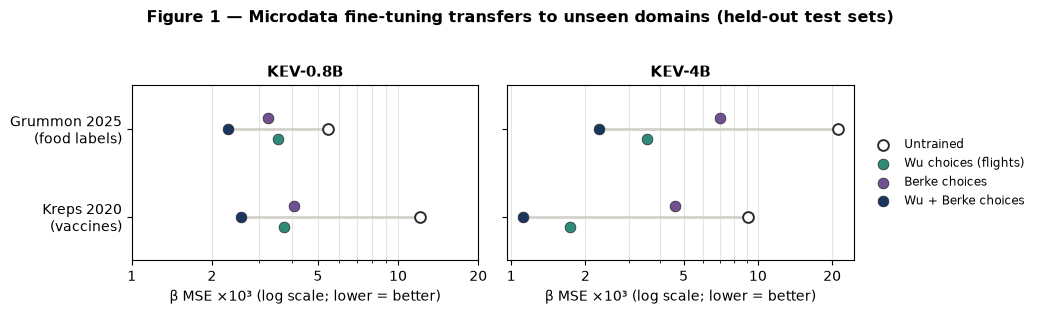

In [128]:
plot_dot_panels(
    models=STEP1_MODELS,
    slugs=STEP1_SLUGS,
    datasets=(
        ("grummon", "Grummon 2025\n(food labels)"),
        ("covid", "Kreps 2020\n(vaccines)"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.12,
        "row3_berke_ce_only": -0.12,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(1, 2, 5, 10, 20),
    title="Figure 1 — Microdata fine-tuning transfers to unseen domains (held-out test sets)",
)

---
## Step 2 — A Published Table Teaches the Study's Slopes (Untrained vs. `Row 2` KL-anchored vs. `Row 2b`)

In [129]:
STEP2_MODELS = ("kev-0.8b", "kev-4b", "kev-9b")
STEP2_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
)
STEP2_SAME_DOMAIN_CELLS = {
    ("row2_wu_table_anchored", "kriner"),
    ("row2b_wu_ce_oracle", "kriner"),
}

print("Table 2 — Wu's published table (8 slopes, KL anchor α = 0.005) vs. Wu's 18,591 choices. Population β MSE (×10³; % change vs. untrained).")
print("Bold = best per model and column.  † Kriner 2026 selects the checkpoint.  ‡ Same domain as the training data (flights).  — = not trained.")
display(build_mse_styler(STEP2_MODELS, STEP2_SLUGS, STEP2_SAME_DOMAIN_CELLS))

Table 2 — Wu's published table (8 slopes, KL anchor α = 0.005) vs. Wu's 18,591 choices. Population β MSE (×10³; % change vs. untrained).
Bold = best per model and column.  † Kriner 2026 selects the checkpoint.  ‡ Same domain as the training data (flights).  — = not trained.


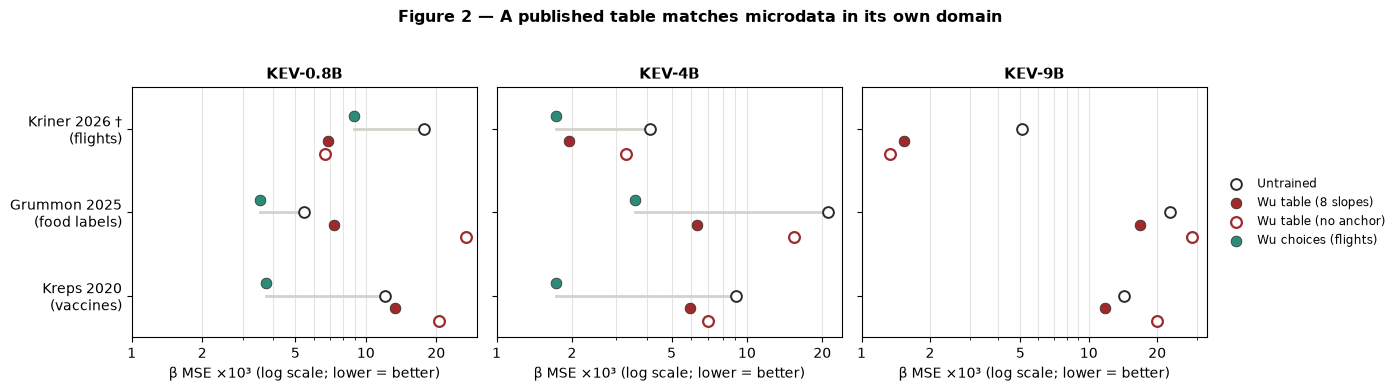

In [130]:
plot_dot_panels(
    models=STEP2_MODELS,
    slugs=(
        "row1_base_untrained",
        "row2_wu_table_anchored",
        "row2_ablation_wu_table_no_kl",
        "row2b_wu_ce_oracle",
    ),
    datasets=(
        ("kriner", "Kriner 2026 †\n(flights)"),
        ("grummon", "Grummon 2025\n(food labels)"),
        ("covid", "Kreps 2020\n(vaccines)"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2_wu_table_anchored": 0.15,
        "row2_ablation_wu_table_no_kl": 0.3,
        "row2b_wu_ce_oracle": -0.15,
    },
    x_ticks=(1, 2, 5, 10, 20),
    title="Figure 2 — A published table matches microdata in its own domain",
)

---
## Step 3 — Your Microdata + Another Study's Table (Untrained vs. `Row 3` vs. `Row 4` KL-anchored vs. `Row 5`)

In [123]:
STEP3_MODELS = ("kev-0.8b", "kev-4b")
STEP3_SLUGS = (
    "row1_base_untrained",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
STEP3_SAME_DOMAIN_CELLS = {
    ("row4_hybrid_berke_ce_wu_table_anchored", "kriner"),
    ("row5_full_berke_wu_ce_oracle", "kriner"),
}

print("Table 3 — Berke choices + Wu's published table (KL anchor α = 0.005) vs. Berke + Wu choices. Population β MSE (×10³; % change vs. untrained).")
print("Bold = best per model and column.  † Kriner 2026 selects the checkpoint.  ‡ Training data include the same domain (Wu flights).")
display(build_mse_styler(STEP3_MODELS, STEP3_SLUGS, STEP3_SAME_DOMAIN_CELLS))

Table 3 — Berke choices + Wu's published table (KL anchor α = 0.005) vs. Berke + Wu choices. Population β MSE (×10³; % change vs. untrained).
Bold = best per model and column.  † Kriner 2026 selects the checkpoint.  ‡ Training data include the same domain (Wu flights).


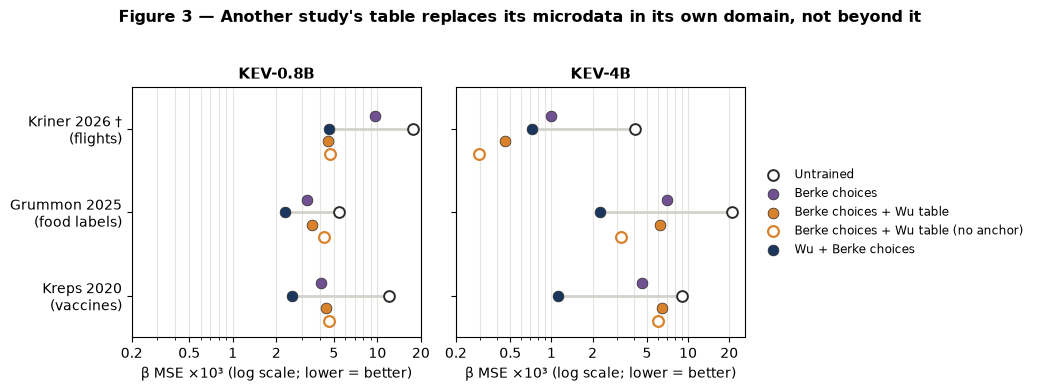

In [124]:
plot_dot_panels(
    models=STEP3_MODELS,
    slugs=(
        "row1_base_untrained",
        "row3_berke_ce_only",
        "row4_hybrid_berke_ce_wu_table_anchored",
        "row4_hybrid_berke_ce_wu_table_no_kl",
        "row5_full_berke_wu_ce_oracle",
    ),
    datasets=(
        ("kriner", "Kriner 2026 †\n(flights)"),
        ("grummon", "Grummon 2025\n(food labels)"),
        ("covid", "Kreps 2020\n(vaccines)"),
    ),
    y_offsets={
        "row1_base_untrained": 0.0,
        "row3_berke_ce_only": -0.15,
        "row4_hybrid_berke_ce_wu_table_anchored": 0.15,
        "row4_hybrid_berke_ce_wu_table_no_kl": 0.3,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.2, 0.5, 1, 2, 5, 10, 20),
    title="Figure 3 — Another study's table replaces its microdata in its own domain, not beyond it",
)

---
## Step 4 — What the Errors Look Like: Kreps 2020 Vaccine Slopes by Attribute

In [ ]:
STEP4_MODELS = ("kev-0.8b", "kev-4b")
STEP4_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2b_wu_ce_oracle",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row5_full_berke_wu_ce_oracle",
)
STEP4_Y_OFFSETS = {
    "row1_base_untrained": -0.28,
    "row2_wu_table_anchored": -0.14,
    "row2b_wu_ce_oracle": 0.0,
    "row4_hybrid_berke_ce_wu_table_anchored": 0.14,
    "row5_full_berke_wu_ce_oracle": 0.28,
}

first_model_betas = covid_betas_by_model[STEP4_MODELS[0]]
kreps_terms = list(first_model_betas[BASE_SLUG].index)
y_positions = np.arange(len(kreps_terms))

fig, axes = plt.subplots(1, len(STEP4_MODELS), figsize=(12.5, 0.55 * len(kreps_terms) + 1.6), sharey=True)
for ax, model_slug in zip(axes, STEP4_MODELS):
    betas_by_slug = covid_betas_by_model[model_slug]
    human_values = betas_by_slug[BASE_SLUG].loc[kreps_terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    for y in y_positions:
        ax.axhspan(y - 0.4, y + 0.4, color=NEUTRALS["grid"], alpha=0.18 * (y % 2), zorder=0, linewidth=0)
    ax.scatter(human_values, y_positions, marker="|", s=420, linewidths=2.4, color=NEUTRALS["text"], zorder=4, label="Human (OLS)")

    for slug in STEP4_SLUGS:
        model_values = betas_by_slug[slug].loc[kreps_terms, "model_pop_beta"].to_numpy(dtype=float)
        y_shifted = y_positions + STEP4_Y_OFFSETS[slug]
        if slug == BASE_SLUG:
            ax.scatter(model_values, y_shifted, s=34, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.2, zorder=3, label=STORY_LABELS[slug])
        else:
            ax.scatter(model_values, y_shifted, s=34, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.4, zorder=3, label=STORY_LABELS[slug])

    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Population β on Kreps 2020 (effect on choice probability)")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kreps_terms, fontsize=9)
axes[0].set_ylim(-0.6, len(kreps_terms) - 0.4)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.suptitle("Figure 4 — Kreps 2020 vaccine slopes by attribute: microdata corrects the endorsement over-weighting; some errors remain", fontsize=11.5, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

---
## Ablation — Without the KL Anchor (to be rebuilt)

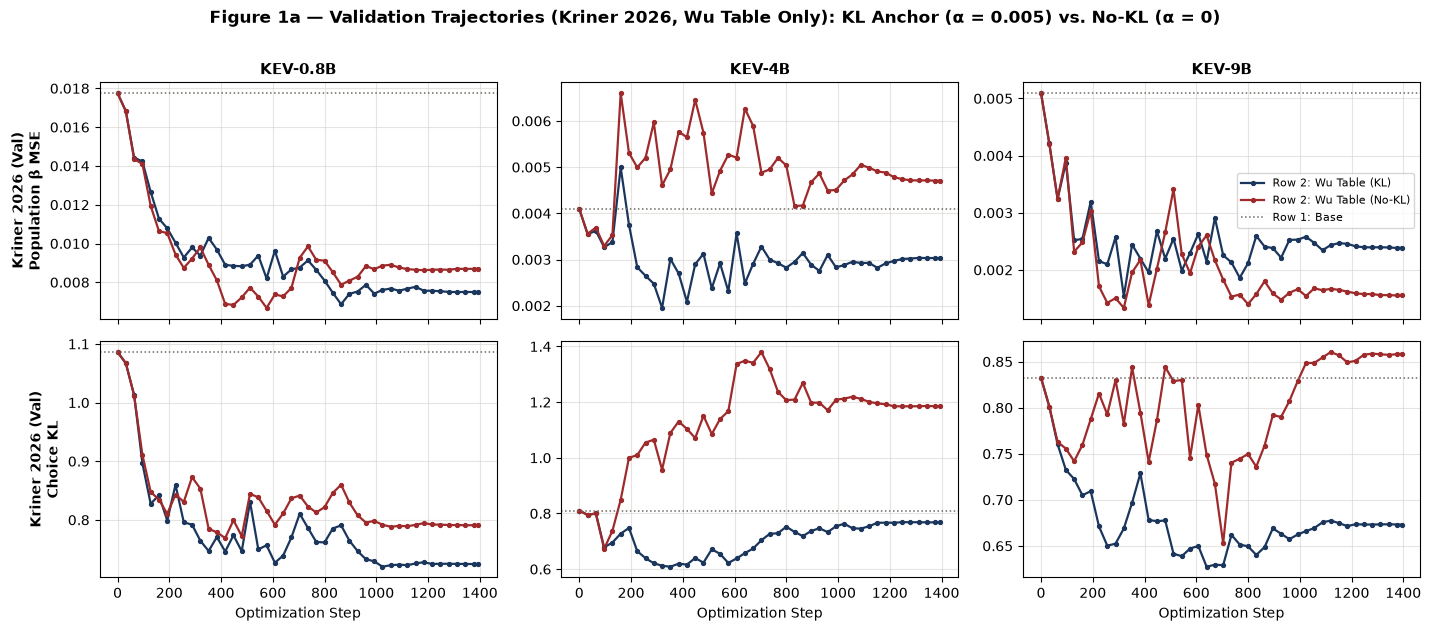

Table 4a — Pre-Flight KL-Anchor Sweep: KEV-0.8B (Wu Table Only, lr = 1e-5)


,KL Drift vs. p₀,Kriner β MSE,Kriner Choice KL,Grummon β MSE (End),Grummon Choice KL (End)
KL Penalty (α),,,,,
Untrained Base,0.00,0.01775,1.085,0.00546,1.059
α = 0,8.94,0.00410,0.862,0.03338,1.349
α = 0.002,1.17,0.00420,0.724,0.00274,0.885
α = 0.005,0.76,0.00352,0.701,0.00565,0.863
α = 0.02,0.40,0.00585,0.720,0.00400,0.946
α = 0.1,0.19,0.00629,0.747,0.00797,0.981
α = 0.5,0.09,0.01033,0.765,0.00938,1.085


Table 4b — Pre-Flight KL-Anchor Sweep: KEV-9B (Wu Table Only, lr = 5e-6)


,KL Drift vs. p₀,Kriner β MSE,Kriner Choice KL,Grummon β MSE (End),Grummon Choice KL (End)
KL Penalty (α),,,,,
Untrained Base,0.00,0.00509,0.832,0.02272,1.238
α = 0,1.76,0.00099,0.792,0.01389,0.974
α = 0.002,1.03,0.00149,0.720,0.00741,0.959
α = 0.005,0.47,0.00158,0.687,0.01020,0.883
α = 0.01,0.35,0.00199,0.637,0.01183,0.916
α = 0.05,0.18,0.00221,0.630,0.01584,0.975


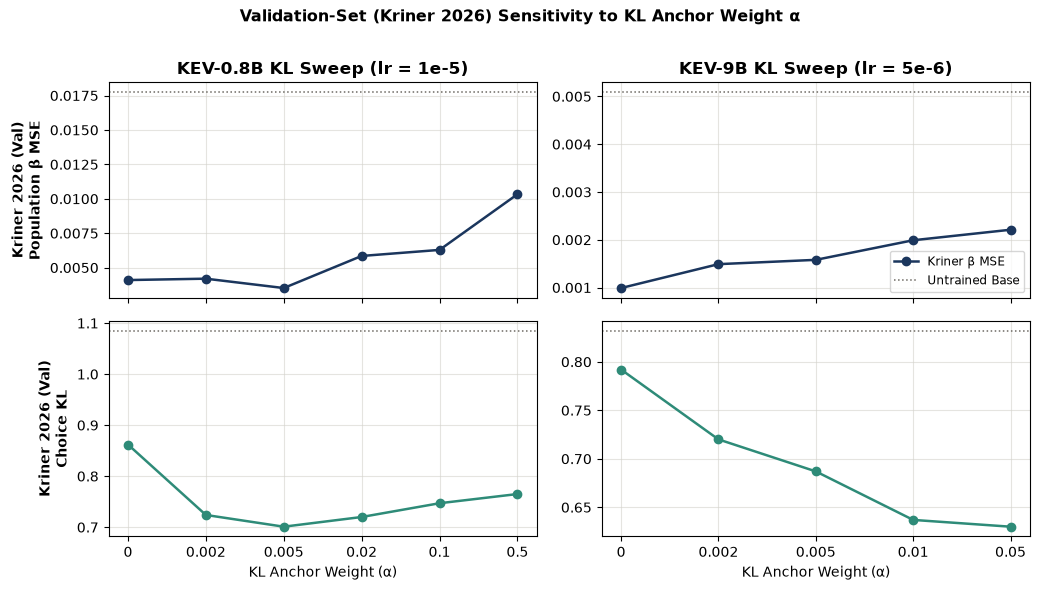

In [91]:
PANEL_SPECS = [
    ("kriner2026/beta_mse", "Kriner 2026 (Val)\nPopulation β MSE"),
    ("kriner2026/kl_loss", "Kriner 2026 (Val)\nChoice KL"),
]


def plot_regime_grid(models: tuple[str, ...], slugs: tuple[str, ...], suptitle: str) -> None:
    fig, axes = plt.subplots(
        len(PANEL_SPECS),
        len(models),
        figsize=(4.8 * len(models), 6.2),
        squeeze=False,
        sharex="col",
    )
    for c_idx, model_slug in enumerate(models):
        base_row = regimes_by_model[model_slug].loc["row1_base_untrained"]
        base_lines = {
            "kriner2026/beta_mse": float(base_row["kriner_mse"]),
            "kriner2026/kl_loss": float(base_row["kriner_kl"]),
        }
        for slug in slugs:
            run_dir = PAPER_RUNS_ROOT / model_slug / slug
            if not (run_dir / "run.json").exists():
                continue
            result = load_paper_run(run_dir)
            if len(result.step_df) == 0:
                continue
            label = SHORT_COL_LABELS[slug]
            for r_idx, (col, row_ylabel) in enumerate(PANEL_SPECS):
                ax = axes[r_idx, c_idx]
                series = result.val_history_df[col].dropna()
                ax.plot(series.index, series.values, marker="o", markersize=2.8, linewidth=1.6, label=label)
                if r_idx == 0:
                    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=10.5, fontweight="bold")
                if c_idx == 0:
                    ax.set_ylabel(row_ylabel, fontsize=10.0, fontweight="bold")
                if r_idx == len(PANEL_SPECS) - 1:
                    ax.set_xlabel("Optimization Step")

        for r_idx, (col, _) in enumerate(PANEL_SPECS):
            ax = axes[r_idx, c_idx]
            ax.axhline(base_lines[col], color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.1, label="Row 1: Base")
            ax.grid(color=NEUTRALS["grid"], alpha=0.6)
            if r_idx == 0 and c_idx == len(models) - 1:
                ax.legend(fontsize=8, loc="best")
    fig.suptitle(suptitle, fontsize=12, fontweight="bold", y=1.01)
    fig.tight_layout()
    plt.show()


plot_regime_grid(
    MODEL_SLUGS,
    ("row2_wu_table_anchored", "row2_ablation_wu_table_no_kl"),
    "Figure 1a — Validation Trajectories (Kriner 2026, Wu Table Only): KL Anchor (α = 0.005) vs. No-KL (α = 0)",
)


plot_regime_grid(
    ("kev-0.8b", "kev-4b"),
    (
        "row3_berke_ce_only",
        "row4_hybrid_berke_ce_wu_table_anchored",
        "row4_hybrid_berke_ce_wu_table_no_kl",
        "row5_full_berke_wu_ce_oracle",
    ),
    "Figure 1b — Validation Trajectories (Kriner 2026, Hybrid): Berke CE vs. Hybrid (KL / No-KL) vs. Full CE Oracle",
)


def collect_alpha_sweep(run_dirs: list[Path]) -> tuple[pd.DataFrame, pd.Series]:
    if len(run_dirs) == 0:
        raise FileNotFoundError("No alpha-sweep run directories supplied")
    step0 = extract_step0_from_run_dir(run_dirs[0], ("wu2025", "kriner2026", "grummon2025"))
    rows = [
        {
            "KL Penalty (α)": "Untrained Base",
            "KL Drift vs. p₀": 0.00,
            "Kriner β MSE": round(float(step0["metrics"]["kriner2026/beta_mse"]), 5),
            "Kriner Choice KL": round(float(step0["metrics"]["kriner2026/kl_loss"]), 3),
            "Grummon β MSE (End)": round(float(step0["metrics"]["grummon2025/beta_mse"]), 5),
            "Grummon Choice KL (End)": round(float(step0["metrics"]["grummon2025/kl_loss"]), 3),
        }
    ]
    alphas: list[float] = []
    keyed = []
    for rd in run_dirs:
        info = run_store.read_run_json(rd)
        keyed.append((float(info["identity"]["config"]["kl_anchor_alpha"]), rd))
    keyed.sort(key=lambda x: x[0])

    for alpha, rd in keyed:
        result = load_paper_run(rd)
        k_metrics, _ = result.best_validation["kriner2026"]
        g_pos_mse = result.val_history_df.loc[result.val_history_df.index > 0, "grummon2025/beta_mse"].dropna()
        g_pos_kl = result.val_history_df.loc[result.val_history_df.index > 0, "grummon2025/kl_loss"].dropna()
        alphas.append(alpha)
        rows.append(
            {
                "KL Penalty (α)": f"α = {alpha:g}",
                "KL Drift vs. p₀": round(float(result.step_df["kl_anchor_loss"].dropna().tail(20).mean()), 2),
                "Kriner β MSE": round(float(k_metrics["beta_mse"]), 5),
                "Kriner Choice KL": round(float(k_metrics["kl_loss"]), 3),
                "Grummon β MSE (End)": round(float(g_pos_mse.iloc[-1]), 5),
                "Grummon Choice KL (End)": round(float(g_pos_kl.iloc[-1]), 3),
            }
        )
    return pd.DataFrame(rows).set_index("KL Penalty (α)"), pd.Series(alphas)


sweep_800m_df, alphas_800m = collect_alpha_sweep(
    [
        *[d for d in (LOCAL_PAPER_RUNS_ROOT / "kl_anchor_800m").iterdir() if (d / "run.json").exists()],
        *[d for d in (PAPER_RUNS_ROOT / "kl_anchor_800m").iterdir() if (d / "run.json").exists()],
    ]
)
sweep_9b_df, alphas_9b = collect_alpha_sweep(
    [d for d in (PAPER_RUNS_ROOT / "kl_anchor_9b").iterdir() if (d / "run.json").exists()]
)

print("Table 4a — Pre-Flight KL-Anchor Sweep: KEV-0.8B (Wu Table Only, lr = 1e-5)")
display(sweep_800m_df)
print("Table 4b — Pre-Flight KL-Anchor Sweep: KEV-9B (Wu Table Only, lr = 5e-6)")
display(sweep_9b_df)

fig, axes = plt.subplots(2, 2, figsize=(10.5, 5.8), sharex="col")
for c_idx, (full_df, alphas, title) in enumerate(
    (
        (sweep_800m_df, alphas_800m, "KEV-0.8B KL Sweep (lr = 1e-5)"),
        (sweep_9b_df, alphas_9b, "KEV-9B KL Sweep (lr = 5e-6)"),
    )
):
    base_s = full_df.loc["Untrained Base"]
    sweep_df = full_df.iloc[1:]
    x_pos = np.arange(len(sweep_df))
    for r_idx, (col, ylabel, color) in enumerate(
        (
            ("Kriner β MSE", "Kriner 2026 (Val)\nPopulation β MSE", PAL[0]),
            ("Kriner Choice KL", "Kriner 2026 (Val)\nChoice KL", PAL[2]),
        )
    ):
        ax = axes[r_idx, c_idx]
        ax.plot(x_pos, sweep_df[col], marker="o", linewidth=1.8, color=color, label=col)
        ax.axhline(float(base_s[col]), color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.1, label="Untrained Base")
        if r_idx == 0:
            ax.set_title(title, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(ylabel, fontweight="bold")
        if r_idx == 1:
            ax.set_xticks(x_pos)
            ax.set_xticklabels([f"{a:g}" for a in alphas])
            ax.set_xlabel("KL Anchor Weight (α)")
        ax.grid(color=NEUTRALS["grid"], alpha=0.6)
        if r_idx == 0 and c_idx == 1:
            ax.legend(fontsize=8.5, loc="best")
fig.suptitle("Validation-Set (Kriner 2026) Sensitivity to KL Anchor Weight α", fontsize=11.5, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

---
## Appendix — Pre-Paper Reference Runs (`v8`, `v12`, `v13`, `v14`)

Cross-check against earlier exploratory runs (`v8`/`v12`/`v14`: `lr = 4e-5`, `1` epoch; `v13`: `α = 0`, `5` epochs).


In [60]:
LEGACY_SPECS = [
    ("kev-0.8b", "v13 Wu Table-Only (No-KL, ep=5, lr=1e-5)", LEGACY_RUNS_ROOT / "train-beta-v13-wu-beta-only-800m" / "beta_only_split_lr=1e-05_S=40_ep=5", load_population_run),
    ("kev-0.8b", "v8 Full CE (Wu+Berke, ep=1, lr=4e-5)", LEGACY_RUNS_ROOT / "train-beta-v8-wu-berke-sample-lrscale-800m" / "lambda=0_lr=4e-05_S=40_ep=1", load_run),
    ("kev-4b", "v12 Full CE (Wu+Berke, ep=1, lr=4e-5)", LEGACY_RUNS_ROOT / "train-beta-v12-wu-berke-scale-4b" / "lambda=0_lr=4e-05_S=40_ep=1", load_run),
    ("kev-4b", "v14 Full CE + Pop-Beta (lambda=0.25, lr=4e-5)", LEGACY_RUNS_ROOT / "train-beta-v14-wu-berke-ce-population-4b" / "lambda=0.25_lr=4e-05_S=40_ep=1", load_ce_population_run),
    ("kev-4b", "v14 Full CE + Pop-Beta (lambda=1.0, lr=4e-5)", LEGACY_RUNS_ROOT / "train-beta-v14-wu-berke-ce-population-4b" / "lambda=1_lr=4e-05_S=40_ep=1", load_ce_population_run),
]

legacy_rows = []
seen_models: set[str] = set()
for model_slug, label, run_dir, loader in LEGACY_SPECS:
    if not (run_dir / "run.json").exists():
        continue
    run_info = run_store.read_run_json(run_dir)
    if run_info["status"] != "finished":
        continue
    if model_slug not in seen_models:
        seen_models.add(model_slug)
        base = extract_step0_from_run_dir(run_dir, VALIDATORS)
        legacy_rows.append(
            {
                "Model": MODEL_DISPLAY[model_slug],
                "Reference Run": "Untrained Base (Step 0)",
                ("Kriner 2026 (Val)", "β MSE"): round(float(base["metrics"]["kriner2026/beta_mse"]), 5),
                ("Kriner 2026 (Val)", "Choice KL"): round(float(base["metrics"]["kriner2026/kl_loss"]), 3),
                ("Grummon 2025 (Test)", "β MSE"): round(float(base["metrics"]["grummon2025/beta_mse"]), 5),
                ("Grummon 2025 (Test)", "Choice KL"): round(float(base["metrics"]["grummon2025/kl_loss"]), 3),
            }
        )
    result = loader(run_dir)
    legacy_rows.append(
        {
            "Model": MODEL_DISPLAY[model_slug],
            "Reference Run": label,
            ("Kriner 2026 (Val)", "β MSE"): round(float(result.best_row["kriner2026/beta_mse"]), 5),
            ("Kriner 2026 (Val)", "Choice KL"): round(float(result.best_row["kriner2026/kl_loss"]), 3),
            ("Grummon 2025 (Test)", "β MSE"): round(float(result.best_row["grummon2025/beta_mse"]), 5),
            ("Grummon 2025 (Test)", "Choice KL"): round(float(result.best_row["grummon2025/kl_loss"]), 3),
        }
    )

legacy_df = pd.DataFrame(legacy_rows).set_index(["Model", "Reference Run"])
legacy_df.columns = pd.MultiIndex.from_tuples(legacy_df.columns)
print("Table A1 — Pre-Paper Exploratory Reference Runs")
display(legacy_df)


Table A1 — Pre-Paper Exploratory Reference Runs


Kriner 2026 (Val)           Grummon 2025 (Test)          
                                                                   β MSE Choice KL               β MSE Choice KL
Model    Reference Run                                                                                          
KEV-0.8B Untrained Base (Step 0)                                 0.01775     1.085             0.00546     1.059
         v13 Wu Table-Only (No-KL, ep=5, lr=1e-5)                0.00396     0.753             0.00844     0.778
         v8 Full CE (Wu+Berke, ep=1, lr=4e-5)                    0.00400     0.632             0.00398     0.888
KEV-4B   Untrained Base (Step 0)                                 0.00410     0.811             0.02105     1.100
         v12 Full CE (Wu+Berke, ep=1, lr=4e-5)                   0.00086     0.584             0.00311     0.840
         v14 Full CE + Pop-Beta (lambda=0.25, lr=4e-5)           0.00105     0.584             0.00530     0.866
         v14 Full CE + Pop-Beta (lambda=1.0, lr=4e-5)            0.00098     0.584             0.00300     0.857

---
## Appendix — Choice KL for Table 1

In [ ]:
table_a2_df = relabel_rows(build_metric_table(STEP1_MODELS, STEP1_SLUGS, "kl").round(3))
print("Table A2 — Choice KL for Table 1 (lower = better). † Kriner 2026 selects the checkpoint.")
display(table_a2_df)

table_a3_df = relabel_rows(build_metric_table(STEP2_MODELS, STEP2_SLUGS, "kl").round(3))
print("Table A3 — Choice KL for Table 2 (lower = better). † Kriner 2026 selects the checkpoint.  NaN = not trained.")
display(table_a3_df)

table_a4_df = relabel_rows(build_metric_table(STEP3_MODELS, STEP3_SLUGS, "kl").round(3))
print("Table A4 — Choice KL for Table 3 (lower = better). † Kriner 2026 selects the checkpoint.")
display(table_a4_df)

---
## Appendix — Kreps 2020 Slopes by Attribute (Table A5)

In [ ]:
KREPS_APPENDIX_SLUGS = (
    "row1_base_untrained",
    "row2_wu_table_anchored",
    "row2_ablation_wu_table_no_kl",
    "row2b_wu_ce_oracle",
    "row3_berke_ce_only",
    "row4_hybrid_berke_ce_wu_table_anchored",
    "row4_hybrid_berke_ce_wu_table_no_kl",
    "row5_full_berke_wu_ce_oracle",
)

for model_slug in STEP4_MODELS:
    betas_by_slug = covid_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[BASE_SLUG]["human_pop_beta"]}
    for slug in KREPS_APPENDIX_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug]["model_pop_beta"]
    kreps_term_df = pd.DataFrame(columns)
    kreps_term_df.index.name = "Vaccine attribute level"
    squared_error = kreps_term_df.sub(kreps_term_df["Human (OLS)"], axis=0).pow(2)
    kreps_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print(f"Table A5 — {MODEL_DISPLAY[model_slug]}: Kreps 2020 population β by attribute (numbers behind Figure 4; includes no-anchor runs)")
    display(kreps_term_df.round(4))